# Desalination units, one at a time: how each works and how it is checked

One section per unit of `difflow_water`'s desalination side: seawater properties, `ROStage`, `ROTrain`, `PressureExchanger`, `WaterPump`, `MVCDesalinator`, `MEDDesalinator`. Each shows what the unit does and then the check that stands behind it, against published data or an independent reference code where one could be read, and says so plainly where none exists. Plant-level design (LCOW optimization, scaling limits) is in notebooks 70 and 73.

| Unit | Checked against |
|---|---|
| seawater properties | TEOS-10, the international seawater standard (GSW reference code) |
| `ROStage`, `ROTrain`, `PressureExchanger`, `WaterPump` | WaterTAP 1.8.0 (an implementation check, not plant data); thermodynamic least work |
| `MVCDesalinator` | WaterTAP 1.8.0 |
| `MEDDesalinator` | nothing published: mass, salt and energy balances only |

In [1]:
import json
from pathlib import Path
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import difflow_water as dw
from difflow_water.chemistry import seawater as sw

ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
BENCH = ROOT / "benchmarks"

## 1. Seawater properties (`difflow_water.seawater`)

The correlations are Sharqawy, Lienhard & Zubair (2010): density (their Eq. 8), specific heat (Eq. 9), osmotic coefficient (Eq. 49), latent heat of water (Eq. 54), read against the paper. Sharqawy et al. fit and quote their accuracy against the IAPWS-2008 Gibbs function, which TEOS-10 implements. `benchmarks/teos10/seawater_teos10.py` evaluates TEOS-10 with its reference code (GSW) on a grid of 5-40 C and 0-70 g/kg; the table compares, per property, the largest deviation with the accuracy Sharqawy et al. state.

In [2]:
ref = json.loads((BENCH / "teos10" / "seawater_teos10.json").read_text())
rows = ref["rows"]
def dev(f, key, skip_fresh=False):
    out = []
    for r in rows:
        if skip_fresh and r["SA_g_kg"] == 0:
            continue
        out.append(float(f(r["t_C"] + 273.15, r["SA_g_kg"] / 1000)) / r[key] - 1)
    return np.max(np.abs(out))
checks = [
    ("density", lambda T, S: sw.density(T, S), "density", False, "0.1 %"),
    ("specific heat", lambda T, S: sw.specific_heat(T, S), "cp", False, "0.28 %"),
    ("latent heat of water", lambda T, S: sw.latent_heat_water(T), "latent_heat", False, "0.01 % (vs IAPWS-95)"),
    ("osmotic pressure", lambda T, S: sw.osmotic_pressure(T, S), "osmotic_pressure", True, "1.4 % (osmotic coefficient)"),
]
print(f"{'property':22s} {'max deviation from TEOS-10':>28s}   stated accuracy (Sharqawy et al.)")
for name, f, key, skip, acc in checks:
    print(f"{name:22s} {dev(f, key, skip) * 100:27.3f} %   {acc}")

# enthalpy: TEOS-10's zero is elsewhere, so compare the heat to warm seawater from
# 15 C (Eq. 43 is valid from 10 C; at 5 C its salt term is 25 % off TEOS-10's)
dh = []
for sa in sorted({r["SA_g_kg"] for r in rows}):
    sub = sorted((r for r in rows if r["SA_g_kg"] == sa and r["t_C"] >= 10.0), key=lambda r: r["t_C"])
    for r in sub[1:]:
        ours = float(sw.enthalpy(r["t_C"] + 273.15, sa / 1000) - sw.enthalpy(sub[0]["t_C"] + 273.15, sa / 1000))
        dh.append(ours / (r["enthalpy"] - sub[0]["enthalpy"]) - 1)
print(f"{'enthalpy rise from 15 C':22s} {np.max(np.abs(dh)) * 100:27.3f} %   0.5 % (vs IAPWS-2008)")

property                 max deviation from TEOS-10   stated accuracy (Sharqawy et al.)


density                                      0.066 %   0.1 %
specific heat                                0.154 %   0.28 %
latent heat of water                         0.150 %   0.01 % (vs IAPWS-95)
osmotic pressure                             0.621 %   1.4 % (osmotic coefficient)
enthalpy rise from 15 C                       0.551 %   0.5 % (vs IAPWS-2008)


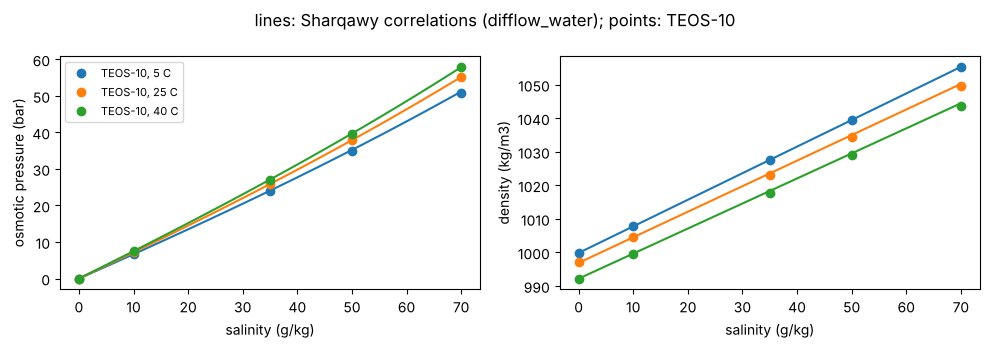

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for t in (5.0, 25.0, 40.0):
    sub = [r for r in rows if r["t_C"] == t]
    sa = np.array([r["SA_g_kg"] for r in sub])
    ax[0].plot(sa, [r["osmotic_pressure"] / 1e5 for r in sub], "o", label=f"TEOS-10, {t:.0f} C")
    s = np.linspace(1e-3, 0.07, 50)
    ax[0].plot(s * 1e3, np.asarray(sw.osmotic_pressure(t + 273.15, s)) / 1e5, "-", color=ax[0].lines[-1].get_color())
    ax[1].plot(sa, [r["density"] for r in sub], "o")
    ax[1].plot(s * 1e3, np.asarray(sw.density(t + 273.15, s)), "-", color=ax[1].lines[-1].get_color())
ax[0].set_xlabel("salinity (g/kg)"); ax[0].set_ylabel("osmotic pressure (bar)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("salinity (g/kg)"); ax[1].set_ylabel("density (kg/m3)")
fig.suptitle("lines: Sharqawy correlations (difflow_water); points: TEOS-10"); fig.tight_layout()

Density, specific heat and osmotic pressure are within the accuracies Sharqawy et al. state; the enthalpy rise is at the edge of its stated 0.5 % (0.55 %, at 70 g/kg between 15 and 25 C). The enthalpy comparison starts at 15 C because Eq. 43 is valid from 10 C: below that its salinity term drifts (at 5 C and 35 g/kg it gives -882 J/kg for the effect of salt, TEOS-10 -1178), so the correlation should not be used for cold seawater enthalpies. The latent heat differs from TEOS-10 by 0.1-0.15 %, where Sharqawy's Eq. 54 claims 0.01 % against IAPWS-95 for pure water. The comparison is not like for like: TEOS-10's latent heat is for evaporation from seawater at the given salinity into vapour (its `latentheat_evap_t`), Eq. 54 for pure water at saturation. For RO the important number is the osmotic pressure, within 0.6 % of TEOS-10.

## 2. `ROStage`: inside a seawater RO element

Solution-diffusion water and salt flux with film-theory concentration polarization, integrated along the membrane area (plug flow); WaterTAP's channel correlations. The profile shows how the driving force collapses toward the outlet: the bulk concentrates, the wall concentrates more (polarization), the osmotic pressure there rises toward the applied pressure, and the flux falls.

recovery 0.420, rejection 0.9931, max CP modulus 1.30, outlet driving pressure 10.4 bar


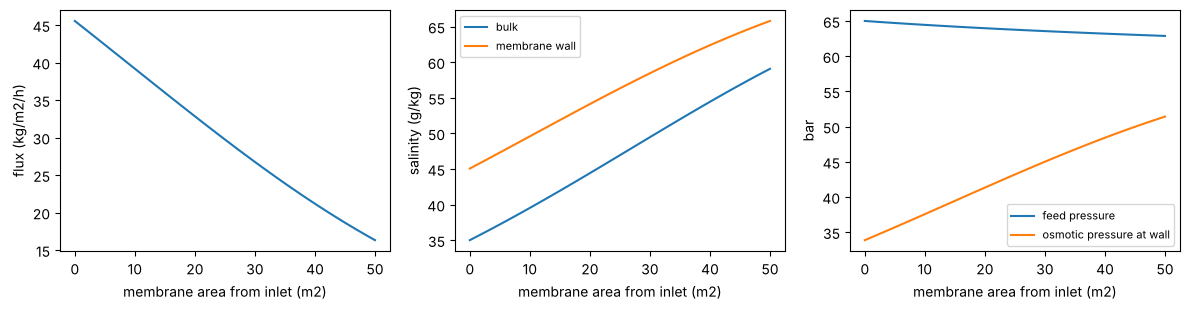

In [4]:
feed = dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035, P=65e5)
ro = dw.ROStage(dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=50.0))
conc, perm, info = ro(feed)
pr = info["profile"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(pr["area"], np.asarray(pr["J_w"]) * 3600, label="water flux"); ax[0].set_ylabel("flux (kg/m2/h)")
ax[1].plot(pr["area"], np.asarray(pr["salinity"]) * 1e3, label="bulk")
ax[1].plot(pr["area"], np.asarray(pr["salinity_wall"]) * 1e3, label="membrane wall"); ax[1].set_ylabel("salinity (g/kg)"); ax[1].legend(fontsize=8)
pi_wall = sw.osmotic_pressure(298.15, jnp.asarray(pr["salinity_wall"]))
ax[2].plot(pr["area"], np.asarray(pr["pressure"]) / 1e5, label="feed pressure")
ax[2].plot(pr["area"], np.asarray(pi_wall) / 1e5, label="osmotic pressure at wall"); ax[2].set_ylabel("bar"); ax[2].legend(fontsize=8)
for a in ax: a.set_xlabel("membrane area from inlet (m2)")
fig.tight_layout()
print(f"recovery {float(info['recovery_vol']):.3f}, rejection {float(info['salt_rejection']):.4f}, "
      f"max CP modulus {float(info['max_cp_modulus']):.2f}, outlet driving pressure {float(info['min_driving_pressure']) / 1e5:.1f} bar")

**Check.** Against WaterTAP's RO1D on four cases (`benchmarks/watertap/compare_swro_px.py`): recovery, permeate salinity, pressure drop and flux within 0.3 % (the docs' comparison section has the table). That checks the implementation against an independent code with the same physics; no published plant or element data set was reachable to check the physics itself. One thermodynamic check needs no data: the energy a plant spends can never be below the least work of separation, which follows from the osmotic pressure (checked against TEOS-10 above),

`W_min / V_permeate = (1/r) int_0^r pi(S_f / (1 - x)) dx`  (reversible, equal-salinity limit; ideal permeate).

In [5]:
def least_work_kWh_m3(r, S=0.035, T=298.15, n=400):
    x = jnp.linspace(0.0, r, n)
    pi = sw.osmotic_pressure(T, S / (1.0 - x))
    return float(jnp.trapezoid(pi, x) / r / 3.6e6)

for P in (55e5, 65e5, 75e5):
    plant = dw.swro_performance(dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035),
                                dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=50.0), P)
    r = float(plant["recovery_vol"])
    print(f"{P / 1e5:.0f} bar: recovery {r:.3f}, plant SEC {float(plant['SEC']):.2f} kWh/m3, "
          f"least work at that recovery {least_work_kWh_m3(r):.2f} kWh/m3")

55 bar: recovery 0.325, plant SEC 2.23 kWh/m3, least work at that recovery 0.88 kWh/m3
65 bar: recovery 0.420, plant SEC 2.47 kWh/m3, least work at that recovery 0.95 kWh/m3
75 bar: recovery 0.500, plant SEC 2.76 kWh/m3, least work at that recovery 1.02 kWh/m3


The plant (high-pressure pump, pressure exchanger, booster) spends 2-3 times the least work, the usual margin for single-stage seawater RO.

## 3. `ROTrain`: stages in series

The concentrate of each stage feeds the next, with an optional booster pump between them. The second stage sees a saltier feed and recovers less per square metre.

In [6]:
stage = dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=30.0)
train = dw.ROTrain(dw.ROTrainParams(stages=[stage, stage], boost=[10e5]))
conc, perm, info = train(feed)
for k, st in enumerate(info["stages"]):
    print(f"stage {k + 1}: water recovery {float(st['recovery_mass_water']):.3f}, feed salinity {float(st['salinity_feed']) * 1e3:.1f} g/kg, "
          f"permeate {float(st['salinity_permeate']) * 1e3:.3f} g/kg")
print(f"train water recovery {float(info['recovery_mass_water']):.3f}, permeate {float(info['salinity_permeate']) * 1e3:.3f} g/kg, "
      f"booster work {float(info['work_boosters']):.0f} W")

stage 1: water recovery 0.304, feed salinity 35.0 g/kg, permeate 0.187 g/kg
stage 2: water recovery 0.305, feed salinity 49.5 g/kg, permeate 0.368 g/kg
train water recovery 0.517, permeate 0.261 g/kg, booster work 874 W


**Check.** No physics of its own: stages in series. Mass balance across the train:

In [7]:
mw_in, ms_in = dw.mass_flows(feed)
mw_c, ms_c = dw.mass_flows(conc); mw_p, ms_p = dw.mass_flows(perm)
print(f"water balance error {float((mw_c + mw_p - mw_in) / mw_in):+.1e}, salt balance error {float((ms_c + ms_p - ms_in) / ms_in):+.1e}")

water balance error -1.1e-16, salt balance error +0.0e+00


## 4. `PressureExchanger`

Hands the brine's pressure to an equal volume of incoming seawater (efficiency `eta`), with optional leakage and mixing; what the exchanger does not need bypasses it to the high-pressure pump. The outlet pressure rises linearly with efficiency; mixing raises the salinity the RO sees.

In [8]:
brine = dw.make_seawater_stream(flow_vol=5e-4, salinity=0.07, P=63e5)
sea = dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035, P=2e5)
for eta, mix in [(0.90, 0.0), (0.95, 0.0), (0.97, 0.0), (0.95, 0.05)]:
    hp, lp, bypass, info = dw.PressureExchanger(dw.PressureExchangerParams(efficiency=eta, mixing=mix))(brine, sea)
    print(f"eta {eta:.2f}, mixing {mix:.2f}: hp feed {float(hp['P']) / 1e5:5.1f} bar, salinity {float(info['salinity_hp_feed']) * 1e3:.2f} g/kg, "
          f"bypass {float(info['bypass_fraction']):.2f} of the seawater")

eta 0.90, mixing 0.00: hp feed  56.9 bar, salinity 35.00 g/kg, bypass 0.50 of the seawater
eta 0.95, mixing 0.00: hp feed  60.0 bar, salinity 35.00 g/kg, bypass 0.50 of the seawater
eta 0.97, mixing 0.00: hp feed  61.2 bar, salinity 35.00 g/kg, bypass 0.50 of the seawater
eta 0.95, mixing 0.05: hp feed  60.0 bar, salinity 36.79 g/kg, bypass 0.50 of the seawater


**Check.** WaterTAP's `PressureExchanger` equations, transcribed; in the plant comparison the exchanger's outlet pressure is within 0.02 % of WaterTAP's, with and without leakage and mixing. Stover (2007) is the device reference; its performance data were not reproduced.

## 5. `WaterPump`

`W = V dP / eta`, isothermal. The check is the identity itself, and WaterTAP's pump (within 0.24 % in the plant).

In [9]:
out, info = dw.WaterPump(dw.WaterPumpParams(outlet_pressure=65e5, efficiency=0.8))(dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035))
V = float(dw.volumetric_flow(dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035)))
print(f"work {float(info['work_mechanical']):.1f} W; V dP / eta = {V * (65e5 - 101325.0) / 0.8:.1f} W")

work 7998.3 W; V dP / eta = 7998.3 W


## 6. `MVCDesalinator`: mechanical vapor compression

The compressor raises the vapor boiled off the brine to a pressure at which it condenses at a temperature above the brine's, so its latent heat drives the next evaporation. By default the pressure ratio is solved so the condensate leaves saturated (the energy balance then closes for any feed); WaterTAP's degrees of freedom (`mode="fixed_pressure_ratio"`) make most designs unphysical, which the next cell shows.

In [10]:
f100 = dw.make_seawater_stream(flow_mass=44.444, salinity=0.1)
base = dw.mvc_performance(f100)
print(f"saturated-condensate design: pressure ratio {float(base['pressure_ratio']):.4f}, SEC {float(base['SEC']):.2f} kWh/m3, "
      f"evaporator {float(base['evaporator_area']):.0f} m2")
for pr in (1.50, 1.56, 1.60, 1.64):
    o = dw.mvc_performance(f100, dw.MVCParams(mode="fixed_pressure_ratio", pressure_ratio=pr))
    print(f"  fixed ratio {pr:.2f}: condensate subcooling {float(o['condensate_subcooling']):+6.2f} K, "
          f"evaporator approach {float(o['evaporator_dT_out']):+6.2f} K, feasible {bool(o['feasible'])}")

saturated-condensate design: pressure ratio 1.6024, SEC 22.06 kWh/m3, evaporator 792 m2


  fixed ratio 1.50: condensate subcooling  +9.82 K, evaporator approach  -4.17 K, feasible False


  fixed ratio 1.56: condensate subcooling  +3.96 K, evaporator approach  +2.67 K, feasible True


  fixed ratio 1.60: condensate subcooling  +0.22 K, evaporator approach  +7.04 K, feasible True


  fixed ratio 1.64: condensate subcooling  -3.38 K, evaporator approach +11.25 K, feasible False


**Check.** Against WaterTAP 1.8.0's MVC flowsheet (`benchmarks/watertap/mvc.py`), live:

In [11]:
ref = json.loads((BENCH / "watertap" / "mvc_reference.json").read_text())["cases"]["optimum"]
i = ref["inputs"]
o = dw.mvc_performance(dw.from_watertap_state(i["feed_H2O_kg_s"], i["feed_TDS_kg_s"], i["T_feed"], i["P_feed"]),
                       dw.MVCParams(mode="fixed_pressure_ratio", recovery=i["recovery"], T_brine=i["T_brine"],
                                    pressure_ratio=i["pressure_ratio"], A_hx_distillate=i["A_hx_distillate"],
                                    A_hx_brine=i["A_hx_brine"], compressor_efficiency=i["compressor_efficiency"],
                                    U_evaporator=i["U_evaporator"], U_hx=i["U_hx"], hx_dP=-7e3))
for k in ["evaporator_area", "compressor_work", "T_condensate", "SEC", "LCOW"]:
    w = ref["outputs"][k]
    print(f"{k:16s} WaterTAP {w:12.6g}   difflow {float(o[k]):12.6g}   rel. diff {(float(o[k]) - w) / w:+.1e}")

evaporator_area  WaterTAP      789.135   difflow      789.135   rel. diff -2.6e-07
compressor_work  WaterTAP  1.77926e+06   difflow  1.77926e+06   rel. diff -4.0e-11
T_condensate     WaterTAP      355.484   difflow      355.484   rel. diff +1.4e-08
SEC              WaterTAP      22.1198   difflow      22.1198   rel. diff +1.1e-07
LCOW             WaterTAP      4.51853   difflow      4.51853   rel. diff +1.5e-08


(`hx_dP = -7e3` reproduces WaterTAP's example, which fixes a +7 kPa pressure *gain* in the preheaters; see the docs.) No published MVC plant data were reachable: this is an implementation check.

## 7. `MEDDesalinator`: parallel-feed multi-effect distillation

Motive steam boils seawater in the first effect; its vapor heats the second, and so on. The gain output ratio (distillate per kg of steam) grows with the number of effects, and in this parallel-feed layout falls well short of it because each effect heats its own share of the feed from the intake temperature.

In [12]:
sea20 = dw.make_seawater_stream(flow_mass=20.0, salinity=0.035)
o = dw.med_performance(sea20, dw.MEDParams(n_effects=6))
print("effect   T (C)   vapor (kg/s)   brine salinity (g/kg)   area (m2)")
for k in range(6):
    print(f"{k + 1:4d} {float(o['T'][k]) - 273.15:9.1f} {float(o['D'][k]):12.3f} {float(o['salinity'][k]) * 1e3:18.1f} {float(o['area'][k]):14.0f}")
print(f"GOR {float(o['GOR']):.2f}, specific thermal energy {float(o['specific_thermal_energy']):.0f} kWh/m3")

effect   T (C)   vapor (kg/s)   brine salinity (g/kg)   area (m2)
   1      65.0        0.823               46.5            187
   2      60.0        0.678               43.9            175
   3      55.0        0.562               42.1            143
   4      50.0        0.476               40.8            118
   5      45.0        0.418               40.0            100
   6      40.0        0.388               39.6             87
GOR 3.35, specific thermal energy 192 kWh/m3


**Check.** No WaterTAP counterpart and no readable published case: the model is mass, salt and energy balances on the checked seawater properties, with no fitted coefficient. What can be checked is that the balances close:

In [13]:
mw, ms = dw.mass_flows(sea20)
D, Bm = float(o["distillate_mass"]), float(dw.mass_flow(o["brine"]))
salt_out = float(dw.mass_flows(o["brine"])[1])
print(f"mass balance error {(D + Bm - float(mw + ms)) / float(mw + ms):+.1e}, salt balance error {(salt_out - float(ms)) / float(ms):+.1e}")
print("GOR < number of effects for every N:", all(float(dw.med_performance(sea20, dw.MEDParams(n_effects=n))["GOR"]) < n for n in (2, 4, 8, 12)))

mass balance error +0.0e+00, salt balance error +0.0e+00


GOR < number of effects for every N: True


## Summary

| Unit | What stands behind it |
|---|---|
| seawater properties | TEOS-10: density 0.07 %, specific heat 0.15 %, osmotic pressure 0.6 %, enthalpy rise 0.55 % above 10 C (Eq. 43's range; stated 0.5 %); latent heat 0.15 % (not like for like); enthalpy below 10 C drifts |
| `ROStage`, `ROTrain`, `PressureExchanger`, `WaterPump` | WaterTAP within 0.3 %; plant energy above the thermodynamic least work; mass balances close |
| `MVCDesalinator` | WaterTAP within 4e-7 |
| `MEDDesalinator` | balances only; no published case |